Case Study: MarketPulse Electronics – Sales Trends and Insights
Dataset Used: Electronics Store Sales Dataset – contains 12 monthly sales files with order dates, product categories, prices, and locations.

MarketPulse Electronics is a mid-sized electronics retail chain operating across major U.S. cities - including New York, San Francisco, Boston, and Los Angeles. Over the past year (January-December), the company has noticed fluctuating profits and seasonal changes in sales patterns.

Their management wants to understand when, what, and where they sell best - and why some months or products perform poorly.

They’ve collected data from their POS (Point of Sale) system. Each transaction includes:

Order ID

Product

Quantity Ordered

Price Each

Order Date

Purchase Address

Your task is to act as a Data Analyst Consultant hired to explore this dataset and generate meaningful insights through visual data storytelling.

Sales Performance Over Time
When are sales highest and lowest throughout the year?

Plot monthly sales trends using a line plot.

Hint: Use groupby('Month')['Sales'].sum() and visualize

In [34]:
import numpy as np
import pandas as pd
import glob
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

In [35]:
files = glob.glob("/content/sample_data/sales-analysis/*.csv")
df = pd.concat((pd.read_csv(f) for f in files), ignore_index=True)


df = df.dropna(how="all")
df = df[df["Order Date"] != "Order Date"]

Highest sales: Dec ($4,613,443.34)
Lowest sales:  Jan ($1,822,256.73)


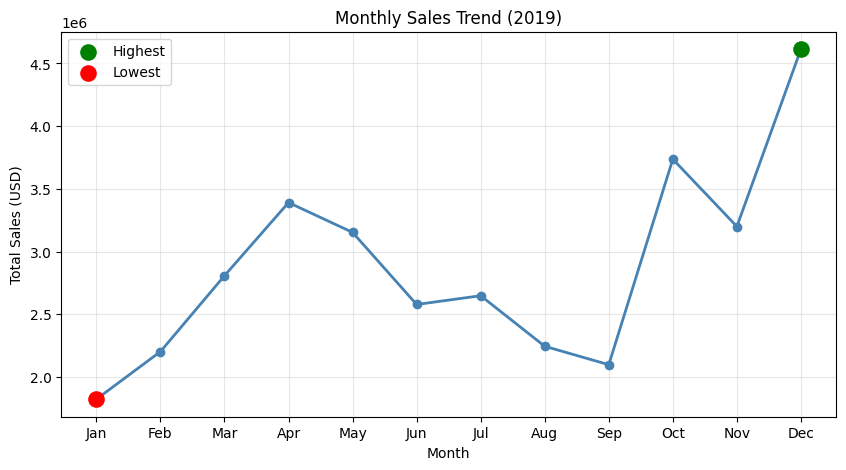

In [36]:
df["Quantity Ordered"] = pd.to_numeric(df["Quantity Ordered"])
df["Price Each"] = pd.to_numeric(df["Price Each"])
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%y %H:%M")


df["Sales"] = df["Quantity Ordered"] * df["Price Each"]
df["Month"] = df["Order Date"].dt.month

# Total sales per month
monthly_sales = df.groupby("Month")["Sales"].sum()

# Find highest and lowest months
best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

print(f"Highest sales: {month_names[best_month-1]} (${monthly_sales.max():,.2f})")
print(f"Lowest sales:  {month_names[worst_month-1]} (${monthly_sales.min():,.2f})")

# Line plot
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="steelblue", linewidth=2)

# Highlight highest and lowest points
plt.scatter(best_month, monthly_sales.max(), color="green", s=120, zorder=5, label="Highest")
plt.scatter(worst_month, monthly_sales.min(), color="red", s=120, zorder=5, label="Lowest")

plt.xticks(monthly_sales.index, [month_names[m-1] for m in monthly_sales.index])
plt.xlabel("Month")
plt.ylabel("Total Sales (USD)")
plt.title("Monthly Sales Trend (2019)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Top-Selling Products
Which products generate the most revenue?

Use a bar chart to visualize total sales by product.

Hint: Compare revenue and quantity ordered — do expensive products sell less frequently?

                               Revenue  Quantity    Price
Product                                                  
Macbook Pro Laptop          8037600.00      4728  1700.00
iPhone                      4794300.00      6849   700.00
ThinkPad Laptop             4129958.70      4130   999.99
Google Phone                3319200.00      5532   600.00
27in 4K Gaming Monitor      2435097.56      6244   389.99
34in Ultrawide Monitor      2355558.01      6199   379.99
Apple Airpods Headphones    2349150.00     15661   150.00
Flatscreen TV               1445700.00      4819   300.00
Bose SoundSport Headphones  1345565.43     13457    99.99
27in FHD Monitor            1132424.50      7550   149.99
Vareebadd Phone              827200.00      2068   400.00
20in Monitor                 454148.71      4129   109.99
LG Washing Machine           399600.00       666   600.00
LG Dryer                     387600.00       646   600.00
Lightning Charging Cable     347094.15     23217    14.95
USB-C Charging

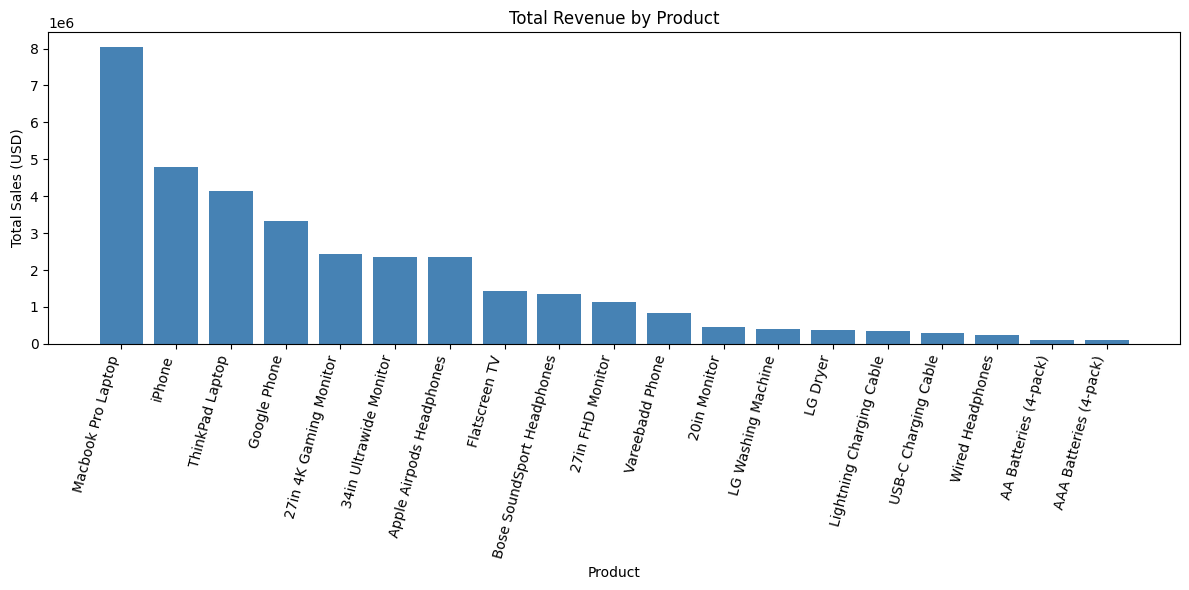

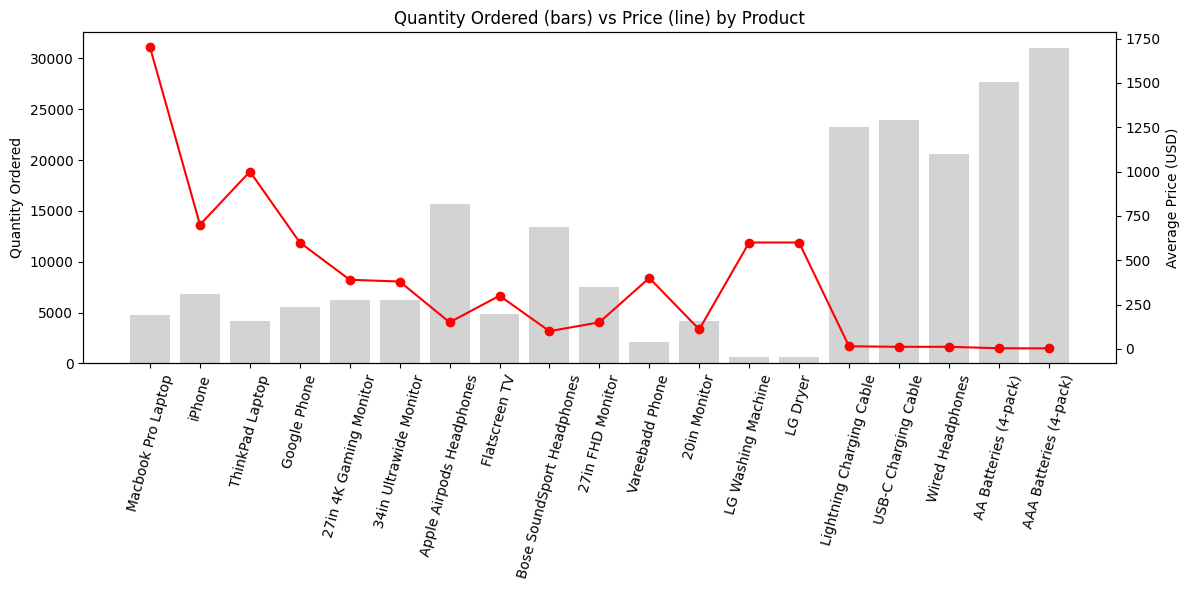

Price vs quantity correlation: -0.6


In [37]:

product_summary = df.groupby("Product").agg(
    Revenue=("Sales", "sum"),
    Quantity=("Quantity Ordered", "sum"),
    Price=("Price Each", "mean")
).sort_values("Revenue", ascending=False)

print(product_summary)

# Bar chart: total revenue by product
plt.figure(figsize=(12, 6))
plt.bar(product_summary.index, product_summary["Revenue"], color="steelblue")
plt.xticks(rotation=75, ha="right")
plt.xlabel("Product")
plt.ylabel("Total Sales (USD)")
plt.title("Total Revenue by Product")
plt.tight_layout()
plt.show()

# Revenue vs quantity, to see if expensive products sell less often
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.bar(product_summary.index, product_summary["Quantity"], color="lightgray", label="Quantity Ordered")
ax1.set_ylabel("Quantity Ordered")
ax1.tick_params(axis="x", rotation=75)

ax2 = ax1.twinx()
ax2.plot(product_summary.index, product_summary["Price"], color="red", marker="o", label="Average Price")
ax2.set_ylabel("Average Price (USD)")

plt.title("Quantity Ordered (bars) vs Price (line) by Product")
fig.tight_layout()
plt.show()

# Correlation between price and quantity
print("Price vs quantity correlation:", product_summary["Price"].corr(product_summary["Quantity"]).round(2))

Sales by City
Which cities contribute most to total revenue?

Create a horizontal bar chart or map-based visualization.

Hint: Extract the city from the purchase address using string manipulation.

City
San Francisco (CA)    8262203.91
Los Angeles (CA)      5452570.80
New York City (NY)    4664317.43
Boston (MA)           3661642.01
Atlanta (GA)          2795498.58
Dallas (TX)           2767975.40
Seattle (WA)          2747755.48
Portland (OR)         1870732.34
Austin (TX)           1819581.75
Portland (ME)          449758.27
Name: Sales, dtype: float64


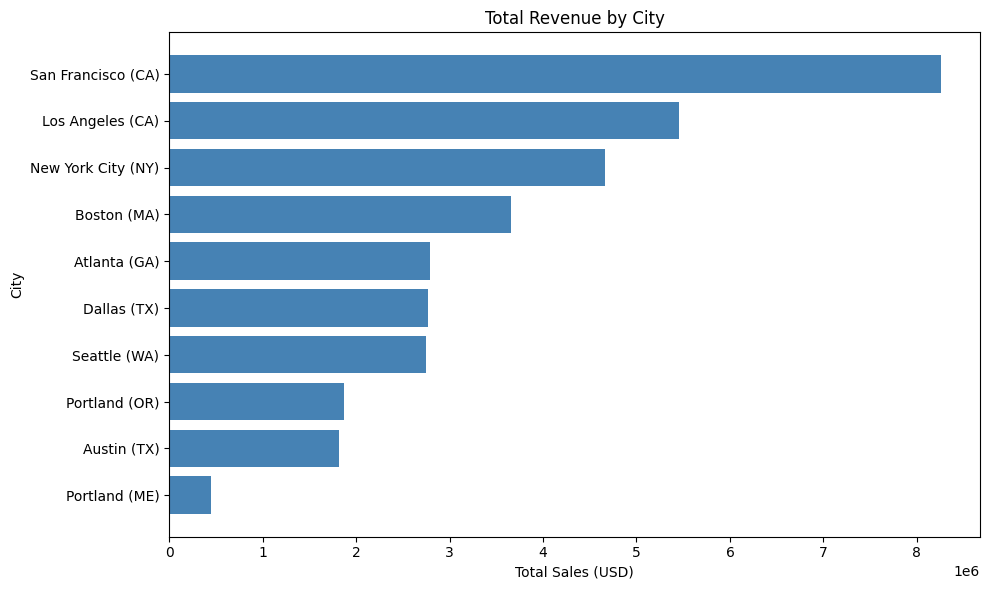

In [38]:
def get_city(address):
    parts = address.split(",")
    city = parts[1].strip()
    state = parts[2].strip().split(" ")[0]
    return f"{city} ({state})"

df["City"] = df["Purchase Address"].apply(get_city)

city_sales = df.groupby("City")["Sales"].sum().sort_values()

print(city_sales.sort_values(ascending=False))

# Horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(city_sales.index, city_sales.values, color="steelblue")
plt.xlabel("Total Sales (USD)")
plt.ylabel("City")
plt.title("Total Revenue by City")
plt.tight_layout()
plt.show()

Product Relationships
Do some products sell together for example- iPhone + Lightning Cable?

Create a scatter plot or heatmap showing co-purchase frequency.

Hint: Look for identical Order IDs containing multiple products

In [40]:
from itertools import combinations
from collections import Counter

Lightning Charging Cable    iPhone                  1011
Google Phone                USB-C Charging Cable     997
Wired Headphones            iPhone                   462
Google Phone                Wired Headphones         422
Apple Airpods Headphones    iPhone                   373
USB-C Charging Cable        Vareebadd Phone          368
Bose SoundSport Headphones  Google Phone             228
USB-C Charging Cable        Wired Headphones         203
Vareebadd Phone             Wired Headphones         149
Lightning Charging Cable    Wired Headphones         129
dtype: int64


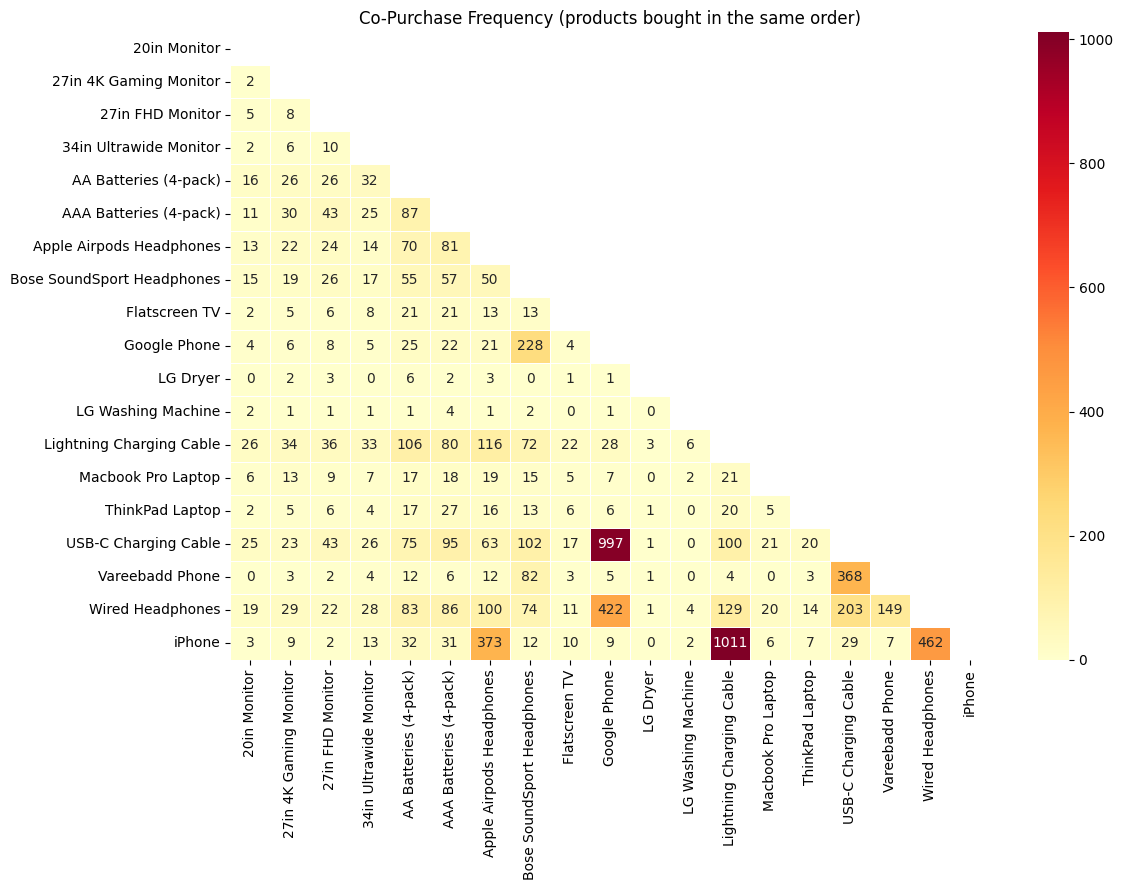

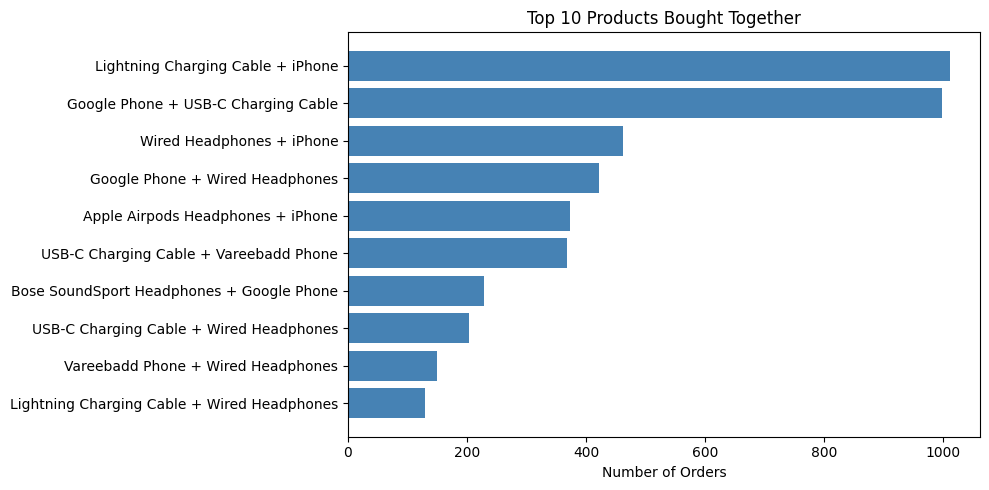

In [41]:
df = df[df["Order ID"].duplicated(keep=False)]

orders = df.groupby("Order ID")["Product"].apply(lambda x: sorted(set(x)))


pair_counts = Counter()
for products in orders:
    for pair in combinations(products, 2):
        pair_counts[pair] += 1

top_pairs = pd.Series(pair_counts).sort_values(ascending=False).head(10)
print(top_pairs)

# Build a symmetric matrix for the heatmap
products = sorted(df["Product"].unique())
matrix = pd.DataFrame(0, index=products, columns=products)
for (a, b), count in pair_counts.items():
    matrix.loc[a, b] = count
    matrix.loc[b, a] = count

# Heatmap (mask the upper triangle to avoid showing every pair twice)
mask = np.triu(np.ones_like(matrix, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(matrix, mask=mask, cmap="YlOrRd", annot=True, fmt="d", linewidths=0.5)
plt.title("Co-Purchase Frequency (products bought in the same order)")
plt.tight_layout()
plt.show()

# Bar chart of the top 10 pairs
plt.figure(figsize=(10, 5))
labels = [f"{a} + {b}" for a, b in top_pairs.index]
plt.barh(labels[::-1], top_pairs.values[::-1], color="steelblue")
plt.xlabel("Number of Orders")
plt.title("Top 10 Products Bought Together")
plt.tight_layout()
plt.show()

Price vs Quantity Relationship
Do cheaper products sell in higher quantities?

Use a scatter plot to explore correlation between price and units sold.

                              Price  Quantity
Product                                      
AAA Batteries (4-pack)         2.99      1251
AA Batteries (4-pack)          3.84      1013
USB-C Charging Cable          11.95      2292
Wired Headphones              11.99      1825
Lightning Charging Cable      14.95      1949
Bose SoundSport Headphones    99.99       827
20in Monitor                 109.99       161
27in FHD Monitor             149.99       298
Apple Airpods Headphones     150.00       982
Flatscreen TV                300.00       179
34in Ultrawide Monitor       379.99       247
27in 4K Gaming Monitor       389.99       251
Vareebadd Phone              400.00       602
LG Dryer                     600.00        25
LG Washing Machine           600.00        28
Google Phone                 600.00      1642
iPhone                       700.00      1867
ThinkPad Laptop              999.99       176
Macbook Pro Laptop          1700.00       197

Pearson correlation:  -0.39
Spear

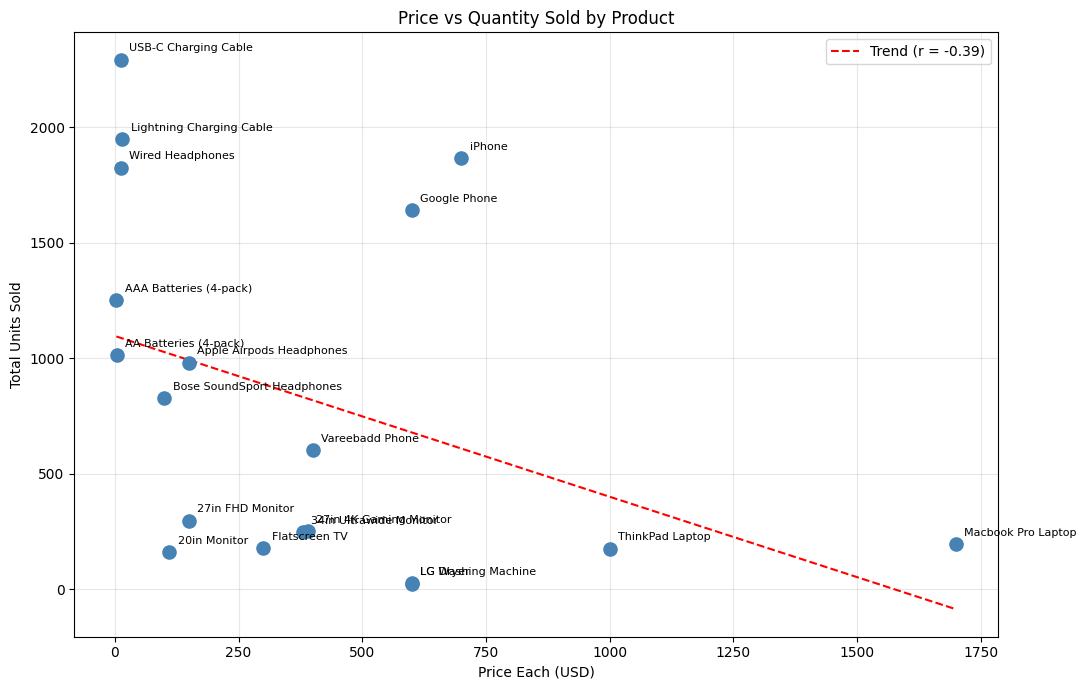

In [43]:
product_summary = df.groupby("Product").agg(
    Price=("Price Each", "mean"),
    Quantity=("Quantity Ordered", "sum")
)

print(product_summary.sort_values("Price"))


pearson = product_summary["Price"].corr(product_summary["Quantity"])
spearman = product_summary["Price"].corr(product_summary["Quantity"], method="spearman")
print(f"\nPearson correlation:  {pearson:.2f}")
print(f"Spearman correlation: {spearman:.2f}")


plt.figure(figsize=(11, 7))
plt.scatter(product_summary["Price"], product_summary["Quantity"], s=90, color="steelblue", zorder=3)


for name, row in product_summary.iterrows():
    plt.annotate(name, (row["Price"], row["Quantity"]), textcoords="offset points",
                 xytext=(6, 6), fontsize=8)


slope, intercept = np.polyfit(product_summary["Price"], product_summary["Quantity"], 1)
x = np.linspace(product_summary["Price"].min(), product_summary["Price"].max(), 100)
plt.plot(x, slope * x + intercept, color="red", linestyle="--", label=f"Trend (r = {pearson:.2f})")

plt.xlabel("Price Each (USD)")
plt.ylabel("Total Units Sold")
plt.title("Price vs Quantity Sold by Product")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Revenue Distribution
Use a histogram or boxplot to visualize how individual transaction revenues vary.

Hint: Identify outliers for example- bulk orders or large purchases.

count    14649.000000
mean       252.541437
std        327.601607
min          2.990000
25%         11.990000
50%         99.990000
75%        600.000000
max       3400.000000
Name: Sales, dtype: float64

Upper outlier threshold: $1,482.01
Number of outliers: 196 (1.3% of transactions)

Products that appear most among outliers:
Product
Macbook Pro Laptop    196
Name: count, dtype: int64

Largest transactions:
      Order ID             Product  Quantity Ordered  Price Each   Sales
22378   181069  Macbook Pro Laptop                 2      1700.0  3400.0
950     279706  Macbook Pro Laptop                 1      1700.0  1700.0
3830    282464  Macbook Pro Laptop                 1      1700.0  1700.0
4021    282645  Macbook Pro Laptop                 1      1700.0  1700.0
5038    283613  Macbook Pro Laptop                 1      1700.0  1700.0
5234    283798  Macbook Pro Laptop                 1      1700.0  1700.0
5257    283821  Macbook Pro Laptop                 1      1700.0  1700.0
579

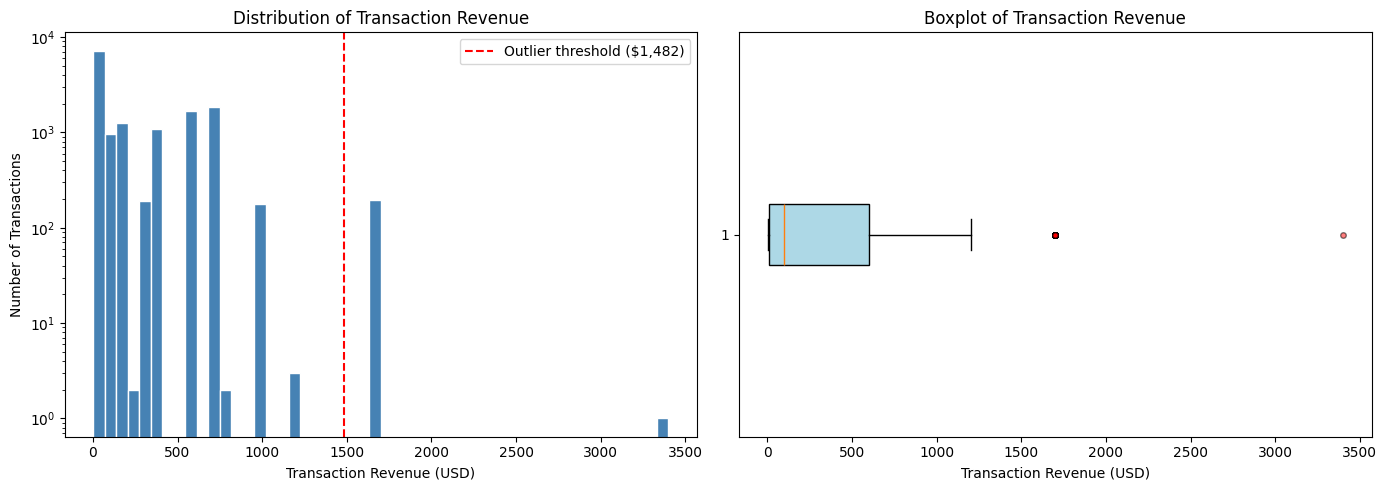

In [44]:
print(df["Sales"].describe())


q1 = df["Sales"].quantile(0.25)
q3 = df["Sales"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
outliers = df[df["Sales"] > upper_limit]

print(f"\nUpper outlier threshold: ${upper_limit:,.2f}")
print(f"Number of outliers: {len(outliers)} ({len(outliers) / len(df) * 100:.1f}% of transactions)")
print("\nProducts that appear most among outliers:")
print(outliers["Product"].value_counts().head(10))

print("\nLargest transactions:")
print(df.nlargest(10, "Sales")[["Order ID", "Product", "Quantity Ordered", "Price Each", "Sales"]])


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["Sales"], bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(upper_limit, color="red", linestyle="--", label=f"Outlier threshold (${upper_limit:,.0f})")
axes[0].set_xlabel("Transaction Revenue (USD)")
axes[0].set_ylabel("Number of Transactions")
axes[0].set_title("Distribution of Transaction Revenue")
axes[0].set_yscale("log")
axes[0].legend()

axes[1].boxplot(df["Sales"], vert=False, patch_artist=True,
                boxprops=dict(facecolor="lightblue"),
                flierprops=dict(marker="o", markerfacecolor="red", markersize=4, alpha=0.5))
axes[1].set_xlabel("Transaction Revenue (USD)")
axes[1].set_title("Boxplot of Transaction Revenue")

plt.tight_layout()
plt.show()